# **Customer Segmentation Project**

### **1. Problem Statement**
Bank belum memiliki strategi yang tepat untuk menawarkan jenis produk yang sesuai dengan profil nasabah yang beragam. Strategi pemasaran saat ini masih bersifat general (satu strategi untuk semua).

### **2. Objective**
Membuat model clustering nasabah untuk mengidentifikasi segmen (kelompok) nasabah berdasarkan profil Demografi dan Finansial. Tujuannya adalah memberikan rekomendasi produk yang spesifik untuk setiap kelompok.

### **Variable Yang Tersedia**
Dari dataset yang dimiliki terdapat beberapa data yang tersedia:

1. GCIF: Unique Identifier Nasabah
2. Area: Lokasi Nasabah (Jakarta, Bogor, Bandung, Surabaya, Jogja, Solo)
3. Jalur_Pembukaan: Touch Points Nasabah Membuka produk (Cabanng, Telemarketing, Aplikasi Digital, Internet Banking)
4. Vintage: Durasi menjadi nasabah (Sejak membuka akun)
5. Usia: Usia nasabah
6. Jenis_kelamin: Laki-laki(1) & Perempuan (1)
7. Status_Perkawinan : Belum menikah(0), Menikah(1), Cerai(2), Janda/Duda(3)
8. Jumlah_Anak : Jumlah Anak Nasabah (Numerik)
9. Pendidikan : Status Pendidikan Terakhir (Tidak Memiliki pendidikan formal[0], SD[1], SMP[2], SMA[3], Sarjana[4], Magister[5], Doktor[6])
10. Produk_Tabungan: Status Kepemilikan Produk(Yes/1, No/0)
11. Produk_Deposito :Status kepemilikan Produk(Yes/1, No/0)
12. Produk_Kartu_Kredit :Status kepemilikan Produk(Yes/1, No/0)
13. Produk_Kredit_Rumah :Status kepemilikan Produk(Yes/1, No/0)
14. Produk_Kredit_Kendaraan :Status kepemilikan Produk(Yes/1, No/0)
15. Produk_Kredit_Dana_Tunai :Status kepemilikan Produk(Yes/1, No/0)
16. Total_Kepemilikan_Produk : Jumlah Produk yang dimiliki(Penjumlahan dari produk-produk)
17. Pendapatan_Tahunan : Rata-rata pendapatan dalam setahun
18. Total_Relationship_balance : Total Asset nasabah dalan cutoff bulan observasi

### **Methodology**
Dalam project ini, pendekatan yang digunakan tidak memisahkan antara data Demografi dan Finansial, melainkan mengintegrasikannya untuk mendapatkan profil nasabah yang utuh (360-degree view).

Alur pengerjaan:
1. **Data Preprocessing:** Pembersihan data, penanganan outlier, dan encoding variabel kategori.
2. **Dimensionality Reduction (PCA):** Menggunakan *Principal Component Analysis* untuk mereduksi dimensi data yang tinggi dan menghilangkan *noise*, sehingga cluster yang terbentuk lebih padat dan terpisah dengan baik.
3. **Modeling:** Menggunakan algoritma **K-Means** pada data hasil reduksi PCA.
4. **Profiling:** Menganalisa karakteristik tiap cluster yang terbentuk untuk menyusun strategi bisnis.

### **Import Package**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
pd.set_option('display.max_columns', None)

### **Data For Clustering**

In [3]:
path_1 = ("clustering_data.csv")
data = pd.read_csv(path_1)
data.dtypes

GCIF                           object
Area                           object
Jalur_Pembukaan                object
Vintage                        object
Usia                          float64
Jenis_Kelamin                  object
Status_Perkawinan              object
Jumlah_Anak                     int64
Pendidikan                     object
Produk_Tabungan                 int64
Produk_Deposito                 int64
Produk_Kartu_Kredit             int64
Produk_Kredit_Rumah             int64
Produk_Kredit_Kendaraan         int64
Produk_Kredit_Dana_Tunai        int64
Total_Kepemilikan_Produk        int64
Pendapatan_Tahunan              int64
Total_Relationship_Balance      int64
dtype: object

### **3. Data Understanding & EDA**
Melakukan pengecekan distribusi data awal untuk memahami karakteristik nasabah berdasarkan lokasi, vintage, dan jalur pembukaan.

In [4]:
data.groupby(('Area'))['Area'].count()

Area
Bandung     6917
Bogor       1191
Jakarta     7017
Jogja       3001
Solo        5001
Surabaya    5002
Name: Area, dtype: int64

In [5]:
numeric_cols = data.select_dtypes(include=[np.number]).columns
data.groupby('Area')[numeric_cols].mean()

,Usia,Jumlah_Anak,Produk_Tabungan,Produk_Deposito,Produk_Kartu_Kredit,Produk_Kredit_Rumah,Produk_Kredit_Kendaraan,Produk_Kredit_Dana_Tunai,Total_Kepemilikan_Produk,Pendapatan_Tahunan,Total_Relationship_Balance
Area,,,,,,,,,,,
Bandung,42.562310,1.296516,0.925401,0.599682,0.329767,0.587393,0.163076,0.537516,3.142836,405.124910,2.454722e+08
Bogor,42.660451,1.366919,0.921075,0.596977,0.324097,0.582704,0.160369,0.554996,3.140218,402.227540,2.499853e+08
Jakarta,42.696995,1.322930,0.925467,0.603534,0.336184,0.590708,0.169873,0.540829,3.166595,406.478552,2.485876e+08
Jogja,42.512422,1.309897,0.934355,0.608464,0.333555,0.594469,0.158614,0.535155,3.164612,402.694768,2.496616e+08
Solo,42.445452,1.270746,0.922416,0.603479,0.337932,0.604679,0.156969,0.540492,3.165967,408.010198,2.507478e+08
Surabaya,42.768980,1.284486,0.927629,0.608357,0.329668,0.585566,0.168533,0.528589,3.148341,409.074370,2.523277e+08


In [6]:
data.groupby(('Vintage'))['Vintage'].count()

Vintage
2 - 3 Tahun    13953
< 1 Tahun       9278
> 4 Tahun       4898
Name: Vintage, dtype: int64

In [7]:
data.groupby('Vintage')[numeric_cols].mean()

,Usia,Jumlah_Anak,Produk_Tabungan,Produk_Deposito,Produk_Kartu_Kredit,Produk_Kredit_Rumah,Produk_Kredit_Kendaraan,Produk_Kredit_Dana_Tunai,Total_Kepemilikan_Produk,Pendapatan_Tahunan,Total_Relationship_Balance
Vintage,,,,,,,,,,,
2 - 3 Tahun,42.578850,1.291694,0.927256,0.607755,0.328531,0.589336,0.163764,0.539311,3.155952,407.679639,2.489367e+08
< 1 Tahun,42.689341,1.294676,0.931235,0.592585,0.336495,0.594201,0.164798,0.523389,3.142703,395.611231,2.486679e+08
> 4 Tahun,42.571866,1.338301,0.912822,0.613107,0.338914,0.592691,0.163536,0.560637,3.181707,422.593508,2.500646e+08


In [8]:
data.groupby('Jalur_Pembukaan')['Jalur_Pembukaan'].count()

Jalur_Pembukaan
Aplikasi Digital     6216
Cabang               5856
Internet Banking     5795
Telemarketing       10262
Name: Jalur_Pembukaan, dtype: int64

In [9]:
data.groupby('Jalur_Pembukaan')[numeric_cols].mean()

,Usia,Jumlah_Anak,Produk_Tabungan,Produk_Deposito,Produk_Kartu_Kredit,Produk_Kredit_Rumah,Produk_Kredit_Kendaraan,Produk_Kredit_Dana_Tunai,Total_Kepemilikan_Produk,Pendapatan_Tahunan,Total_Relationship_Balance
Jalur_Pembukaan,,,,,,,,,,,
Aplikasi Digital,42.442089,1.292149,0.930180,0.598456,0.323681,0.593147,0.165541,0.535714,3.146718,405.278314,2.489950e+08
Cabang,42.560627,1.308743,0.924180,0.610143,0.325478,0.583675,0.153518,0.544740,3.141735,409.923156,2.456661e+08
Internet Banking,42.723992,1.302502,0.928387,0.597929,0.347368,0.598965,0.169802,0.531493,3.173943,406.593270,2.517532e+08
Telemarketing,42.676514,1.300526,0.923309,0.606412,0.334730,0.590821,0.165952,0.538589,3.159813,404.674527,2.494725e+08


In [10]:
data.groupby(('Status_Perkawinan'))['Status_Perkawinan'].count()


Status_Perkawinan
Belum Menikah     8168
Cerai             4077
Janda/Duda        4045
Menikah          11839
Name: Status_Perkawinan, dtype: int64

In [11]:
data.groupby('Status_Perkawinan')[numeric_cols].mean()

,Usia,Jumlah_Anak,Produk_Tabungan,Produk_Deposito,Produk_Kartu_Kredit,Produk_Kredit_Rumah,Produk_Kredit_Kendaraan,Produk_Kredit_Dana_Tunai,Total_Kepemilikan_Produk,Pendapatan_Tahunan,Total_Relationship_Balance
Status_Perkawinan,,,,,,,,,,,
Belum Menikah,39.571621,0.000000,1.000000,0.596107,0.333374,0.331660,0.160749,0.499633,2.921523,420.636141,2.423448e+08
Cerai,50.226883,2.003679,1.000000,0.607555,0.337258,0.509688,0.172676,0.389747,3.016924,426.269070,2.393499e+08
Janda/Duda,NaN,1.201978,1.000000,0.609889,0.337948,0.597281,0.161187,0.401731,3.108035,289.648208,2.474754e+08
Menikah,42.084467,1.989948,0.824309,0.605457,0.329504,0.797027,0.164372,0.661542,3.382211,429.378833,2.575412e+08


### **4. Data Preprocessing**
Tahap ini meliputi pembersihan data dari nilai kosong (*missing values*), duplikat, dan penanganan *outlier* agar model tidak bias.

In [12]:
data.isnull().sum()

GCIF                             0
Area                             0
Jalur_Pembukaan                  0
Vintage                          0
Usia                          4045
Jenis_Kelamin                    0
Status_Perkawinan                0
Jumlah_Anak                      0
Pendidikan                       0
Produk_Tabungan                  0
Produk_Deposito                  0
Produk_Kartu_Kredit              0
Produk_Kredit_Rumah              0
Produk_Kredit_Kendaraan          0
Produk_Kredit_Dana_Tunai         0
Total_Kepemilikan_Produk         0
Pendapatan_Tahunan               0
Total_Relationship_Balance       0
dtype: int64

In [13]:
# Preserve Janda/Duda demographic (100% missing Usia) via group-aware median imputation
group_age_medians = data.groupby("Status_Perkawinan")["Usia"].transform("median")
data["Usia"] = data["Usia"].fillna(group_age_medians).fillna(data["Usia"].median())
# Drop rows only if other mandatory columns still contain nulls
data = data.dropna().reset_index(drop=True)
print(f"Rows preserved after age imputation: {len(data)}")


In [14]:
data.isnull().sum()

GCIF                          0
Area                          0
Jalur_Pembukaan               0
Vintage                       0
Usia                          0
Jenis_Kelamin                 0
Status_Perkawinan             0
Jumlah_Anak                   0
Pendidikan                    0
Produk_Tabungan               0
Produk_Deposito               0
Produk_Kartu_Kredit           0
Produk_Kredit_Rumah           0
Produk_Kredit_Kendaraan       0
Produk_Kredit_Dana_Tunai      0
Total_Kepemilikan_Produk      0
Pendapatan_Tahunan            0
Total_Relationship_Balance    0
dtype: int64

In [15]:
data.duplicated().sum()

0

#### **4.1. Outlier Handling**
Menggunakan metode Z-Score untuk membuang data ekstrim yang dapat mengganggu pembentukan cluster.

In [16]:
data.count()

GCIF                          24084
Area                          24084
Jalur_Pembukaan               24084
Vintage                       24084
Usia                          24084
Jenis_Kelamin                 24084
Status_Perkawinan             24084
Jumlah_Anak                   24084
Pendidikan                    24084
Produk_Tabungan               24084
Produk_Deposito               24084
Produk_Kartu_Kredit           24084
Produk_Kredit_Rumah           24084
Produk_Kredit_Kendaraan       24084
Produk_Kredit_Dana_Tunai      24084
Total_Kepemilikan_Produk      24084
Pendapatan_Tahunan            24084
Total_Relationship_Balance    24084
dtype: int64

In [17]:
from scipy import stats

z_cols = ["Usia", "Pendapatan_Tahunan", "Total_Relationship_Balance"]
z_scores = stats.zscore(data[z_cols])
# Two-sided Z-score filter removes both extreme upper and lower outliers
data = data[(np.abs(z_scores) < 3).all(axis=1)].reset_index(drop=True)


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
data.count()

GCIF                          23704
Area                          23704
Jalur_Pembukaan               23704
Vintage                       23704
Usia                          23704
Jenis_Kelamin                 23704
Status_Perkawinan             23704
Jumlah_Anak                   23704
Pendidikan                    23704
Produk_Tabungan               23704
Produk_Deposito               23704
Produk_Kartu_Kredit           23704
Produk_Kredit_Rumah           23704
Produk_Kredit_Kendaraan       23704
Produk_Kredit_Dana_Tunai      23704
Total_Kepemilikan_Produk      23704
Pendapatan_Tahunan            23704
Total_Relationship_Balance    23704
dtype: int64

In [19]:
data0 = data.copy()

### **Filtering Data**
 

In [20]:
data0 = data0.drop(columns=['GCIF', 'Jalur_Pembukaan']).reset_index(drop=True)

In [21]:
data0 = data0.reset_index()
data0

,index,Area,Vintage,Usia,Jenis_Kelamin,Status_Perkawinan,Jumlah_Anak,Pendidikan,Produk_Tabungan,Produk_Deposito,Produk_Kartu_Kredit,Produk_Kredit_Rumah,Produk_Kredit_Kendaraan,Produk_Kredit_Dana_Tunai,Total_Kepemilikan_Produk,Pendapatan_Tahunan,Total_Relationship_Balance
0,0,Bogor,< 1 Tahun,69.0,Laki-laki,Menikah,3,Doktor,1,0,0,0,0,0,1,747,44607
1,1,Jakarta,< 1 Tahun,23.0,Laki-laki,Belum Menikah,0,Doktor,1,0,0,0,0,0,1,198,10668586
2,2,Surabaya,< 1 Tahun,30.0,Laki-laki,Belum Menikah,0,Doktor,1,0,0,0,0,0,1,280,299076075
3,3,Bandung,< 1 Tahun,45.0,Laki-laki,Belum Menikah,0,Doktor,1,0,0,0,0,0,1,431,417250579
4,4,Bandung,< 1 Tahun,34.0,Perempuan,Belum Menikah,0,Doktor,1,0,0,0,0,0,1,184,453573593
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23699,23699,Jogja,2 - 3 Tahun,41.0,Perempuan,Belum Menikah,0,Tidak Sekolah Formal,1,1,1,1,1,1,6,325,167993431
23700,23700,Solo,2 - 3 Tahun,28.0,Laki-laki,Menikah,0,Tidak Sekolah Formal,1,1,1,1,1,1,6,290,189632802
23701,23701,Jakarta,2 - 3 Tahun,52.0,Laki-laki,Belum Menikah,0,Tidak Sekolah Formal,1,1,1,1,1,1,6,734,166478751
23702,23702,Solo,2 - 3 Tahun,47.0,Perempuan,Menikah,0,Tidak Sekolah Formal,1,1,1,1,1,1,6,364,600734753


In [22]:
mapping_vintage = {
    '< 1 Tahun': 0.5,
    '2 - 3 Tahun': 2.5,
    '> 4 Tahun': 5.0
}

data0['Vintage'] = data0['Vintage'].map(mapping_vintage).fillna(2.5)
print(data0['Vintage'].dtype)
data0['Vintage'].head()


float64


0    0.5
1    0.5
2    0.5
3    0.5
4    0.5
Name: Vintage, dtype: float64

### **5. Feature Engineering**
Proses penyiapan fitur (variabel) sebelum masuk ke pemodelan:
1. **Feature Selection:** Memilih kolom yang relevan.
2. **Encoding:** Mengubah data kategori menjadi angka.
3. **Scaling:** Menyamakan skala data numerik.

In [23]:
cols_cat = ['Area', 'Jenis_Kelamin', 'Status_Perkawinan', 'Pendidikan']
data1 = data0[cols_cat]

print("Kolom Kategorikal:", data1.columns.tolist())


Kolom Kategorikal: ['Area', 'Jenis_Kelamin', 'Status_Perkawinan', 'Pendidikan']


In [24]:
produk_cols = [
    'Produk_Tabungan', 'Produk_Deposito', 'Produk_Kartu_Kredit',
    'Produk_Kredit_Rumah', 'Produk_Kredit_Kendaraan', 'Produk_Kredit_Dana_Tunai'
]

fin_cols = ['Pendapatan_Tahunan', 'Total_Relationship_Balance']


In [25]:

cols_num = ['Vintage', 'Usia', 'Jumlah_Anak'] + produk_cols + fin_cols
data2 = data0[cols_num]

print("Kolom Numerik Final:", data2.columns.tolist())

Kolom Numerik Final: ['Vintage', 'Usia', 'Jumlah_Anak', 'Produk_Tabungan', 'Produk_Deposito', 'Produk_Kartu_Kredit', 'Produk_Kredit_Rumah', 'Produk_Kredit_Kendaraan', 'Produk_Kredit_Dana_Tunai', 'Pendapatan_Tahunan', 'Total_Relationship_Balance']


#### **5.1. Encoding Categorical Data**
- **Ordinal Encoding:** Untuk 'Pendidikan' (karena memiliki urutan tingkatan).
- **One-Hot Encoding:** Untuk variabel kategori lain (Area, Status Perkawinan, dll).

In [26]:
mapping_pendidikan = {
    'Tidak Sekolah Formal': 0, 'SD': 1, 'SMP': 2, 'SMA': 3,
    'Sarjana': 4, 'Magister': 5, 'Doktor': 6
}
data0['Pendidikan_Map'] = data0['Pendidikan'].map(mapping_pendidikan).fillna(3)
cols_cat = ['Area', 'Jenis_Kelamin', 'Status_Perkawinan']
data1 = pd.get_dummies(data0[cols_cat])


#### **5.2. Standardization**
Menggunakan `StandardScaler` agar variabel dengan nilai besar (seperti Pendapatan) tidak mendominasi variabel dengan nilai kecil (seperti Usia).

In [27]:
from sklearn.preprocessing import StandardScaler

data_num_ord = pd.concat([data2, data0[["Pendidikan_Map"]]], axis=1)
predname_num = data_num_ord.columns

scaler = StandardScaler()
X_num = pd.DataFrame(
    scaler.fit_transform(data_num_ord),
    columns=predname_num,
    index=data0.index,
)
X_num.head()


,Vintage,Usia,Jumlah_Anak,Produk_Tabungan,Produk_Deposito,Produk_Kartu_Kredit,Produk_Kredit_Rumah,Produk_Kredit_Kendaraan,Produk_Kredit_Dana_Tunai,Pendapatan_Tahunan,Total_Relationship_Balance
0,-1.214802,2.128871,1.138806,0.309817,-1.218054,-0.693102,-1.187092,-0.434541,-1.116422,1.768927,-1.664899
1,-1.214802,-1.588780,-0.884347,0.309817,-1.218054,-0.693102,-1.187092,-0.434541,-1.116422,-1.258586,-1.591383
2,-1.214802,-1.023051,-0.884347,0.309817,-1.218054,-0.693102,-1.187092,-0.434541,-1.116422,-0.806389,0.404361
3,-1.214802,0.189227,-0.884347,0.309817,-1.218054,-0.693102,-1.187092,-0.434541,-1.116422,0.026315,1.222113
4,-1.214802,-0.699777,-0.884347,0.309817,-1.218054,-0.693102,-1.187092,-0.434541,-1.116422,-1.335791,1.473464


In [28]:
X_num

,Vintage,Usia,Jumlah_Anak,Produk_Tabungan,Produk_Deposito,Produk_Kartu_Kredit,Produk_Kredit_Rumah,Produk_Kredit_Kendaraan,Produk_Kredit_Dana_Tunai,Pendapatan_Tahunan,Total_Relationship_Balance
0,-1.214802,2.128871,1.138806,0.309817,-1.218054,-0.693102,-1.187092,-0.434541,-1.116422,1.768927,-1.664899
1,-1.214802,-1.588780,-0.884347,0.309817,-1.218054,-0.693102,-1.187092,-0.434541,-1.116422,-1.258586,-1.591383
2,-1.214802,-1.023051,-0.884347,0.309817,-1.218054,-0.693102,-1.187092,-0.434541,-1.116422,-0.806389,0.404361
3,-1.214802,0.189227,-0.884347,0.309817,-1.218054,-0.693102,-1.187092,-0.434541,-1.116422,0.026315,1.222113
4,-1.214802,-0.699777,-0.884347,0.309817,-1.218054,-0.693102,-1.187092,-0.434541,-1.116422,-1.335791,1.473464
...,...,...,...,...,...,...,...,...,...,...,...
23699,0.060443,-0.134047,-0.884347,0.309817,0.820982,1.442790,0.842395,2.301279,0.895718,-0.558233,-0.502715
23700,0.060443,-1.184688,-0.884347,0.309817,0.820982,1.442790,0.842395,2.301279,0.895718,-0.751243,-0.352973
23701,0.060443,0.754956,-0.884347,0.309817,0.820982,1.442790,0.842395,2.301279,0.895718,1.697237,-0.513196
23702,0.060443,0.350864,-0.884347,0.309817,0.820982,1.442790,0.842395,2.301279,0.895718,-0.343163,2.491801


In [29]:
# Single-pass scaling: combine one-hot categories with standardized numeric + ordinal features
data_final = pd.concat([data1.astype(float), X_num], axis=1)
print(f"Final feature matrix shape: {data_final.shape}")


### **6. Dimensionality Reduction (PCA)**
Menggunakan **Principal Component Analysis (PCA)** untuk:
1. Meringkas fitur yang banyak menjadi komponen utama yang padat informasi.
2. Menghindari *Curse of Dimensionality* (terlalu banyak kolom 0/1).
3. Meningkatkan performa algoritma K-Means.

### **7. Modeling: K-Means Clustering**
Melakukan pengelompokan nasabah menggunakan algoritma K-Means berdasarkan data hasil reduksi PCA.

In [30]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3, random_state=42)
data_pca = pca.fit_transform(data_final)

print(f"Dimensi awal: {data_final.shape[1]}")
print(f"Dimensi setelah PCA: {data_pca.shape[1]}")


Dimensi awal: 23
Dimensi setelah PCA: 3


In [32]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=3, random_state=42)
labels_pca = kmeans.fit_predict(data_pca) 
score_pca = silhouette_score(data_pca, labels_pca)
print(f"Silhouette Score dengan PCA: {score_pca}")

data0['Cluster_PCA'] = labels_pca

Silhouette Score dengan PCA: 0.3911651677995721


### **8. Evaluation & Profiling**
Menganalisa karakteristik tiap cluster yang terbentuk untuk mengambil kesimpulan bisnis (*Business Insight*).

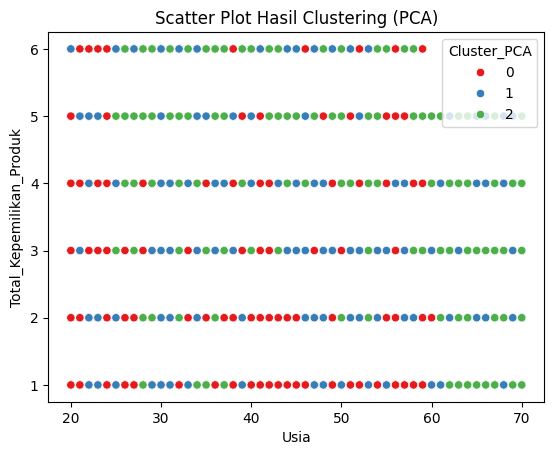

In [33]:
sns.scatterplot(data=data0, x='Usia', y='Total_Kepemilikan_Produk', hue='Cluster_PCA', palette='Set1')
plt.title('Scatter Plot Hasil Clustering (PCA)')
plt.show()

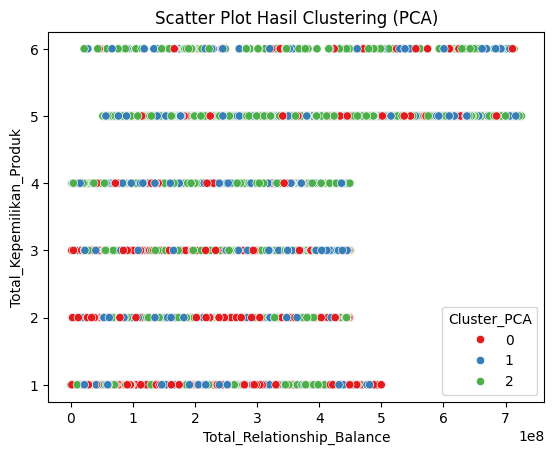

In [34]:
sns.scatterplot(data=data0, x='Total_Relationship_Balance', y='Total_Kepemilikan_Produk', hue='Cluster_PCA', palette='Set1')
plt.title('Scatter Plot Hasil Clustering (PCA)')
plt.show()

In [35]:
cluster_means = data0.groupby('Cluster_PCA')[
    ['Usia', 'Jumlah_Anak', 
     'Produk_Tabungan', 'Produk_Deposito', 'Produk_Kartu_Kredit', 
     'Produk_Kredit_Rumah', 'Produk_Kredit_Kendaraan', 'Produk_Kredit_Dana_Tunai',
     'Total_Relationship_Balance']
].mean()

cluster_means

,Usia,Jumlah_Anak,Produk_Tabungan,Produk_Deposito,Produk_Kartu_Kredit,Produk_Kredit_Rumah,Produk_Kredit_Kendaraan,Produk_Kredit_Dana_Tunai,Total_Relationship_Balance
Cluster_PCA,,,,,,,,,
0,42.096792,0.338070,1.000000,0.593416,0.332302,0.311480,0.160383,0.446117,2.328876e+08
1,42.446581,1.310960,0.910885,0.596531,0.316365,0.590246,0.157240,0.563223,2.394996e+08
2,43.316088,2.112384,0.841782,0.601389,0.325579,0.804977,0.159028,0.636574,2.480717e+08


In [36]:
cluster_profile = data0.groupby('Cluster_PCA')[
    ['Usia', 'Jumlah_Anak', 'Vintage',
     'Produk_Tabungan', 'Produk_Deposito', 'Produk_Kartu_Kredit', 
     'Produk_Kredit_Rumah', 'Produk_Kredit_Kendaraan', 'Produk_Kredit_Dana_Tunai',
     'Pendapatan_Tahunan', 'Total_Relationship_Balance']
].mean()

print("\n=== DISTRIBUSI PENDIDIKAN PER CLUSTER ===")
print(pd.crosstab(data0['Cluster_PCA'], data0['Pendidikan'], normalize='index'))


=== DISTRIBUSI PENDIDIKAN PER CLUSTER ===
Pendidikan     Doktor  Magister        SD       SMA       SMP   Sarjana  \
Cluster_PCA                                                               
0            0.089336  0.086663  0.183174  0.178250  0.095526  0.275464   
1            0.093891  0.089618  0.190171  0.178482  0.086853  0.273127   
2            0.092361  0.086690  0.181250  0.181713  0.094329  0.273958   

Pendidikan   Tidak Sekolah Formal  
Cluster_PCA                        
0                        0.091587  
1                        0.087858  
2                        0.089699  


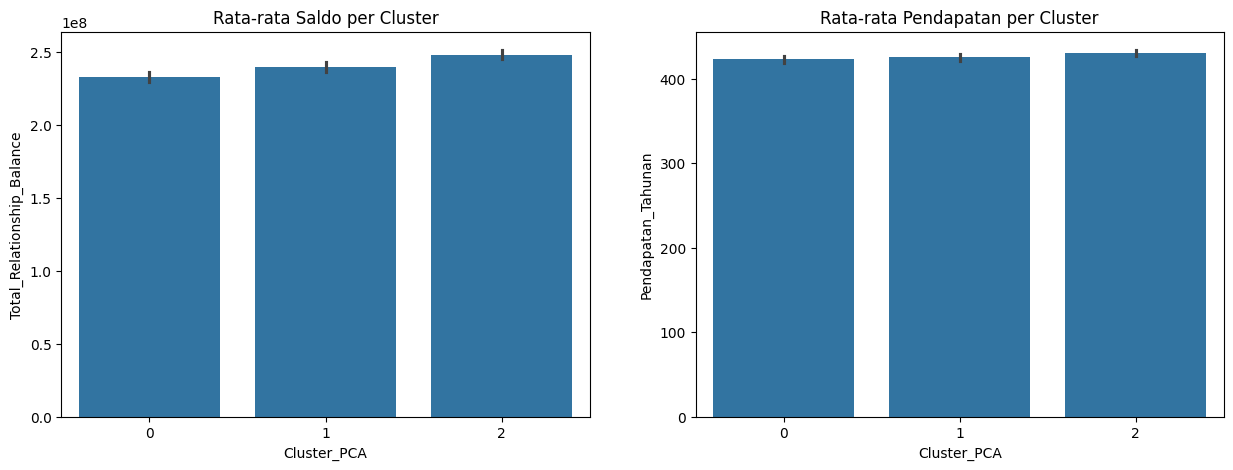

In [37]:

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(x='Cluster_PCA', y='Total_Relationship_Balance', data=data0, ax=ax[0])
ax[0].set_title('Rata-rata Saldo per Cluster')

sns.barplot(x='Cluster_PCA', y='Pendapatan_Tahunan', data=data0, ax=ax[1])
ax[1].set_title('Rata-rata Pendapatan per Cluster')

plt.show()

In [38]:
print(data0.groupby('Cluster_PCA')[['Usia', 'Pendapatan_Tahunan', 'Total_Relationship_Balance']].mean())


                  Usia  Pendapatan_Tahunan  Total_Relationship_Balance
Cluster_PCA                                                           
0            42.096792          422.674451                2.328876e+08
1            42.446581          425.173077                2.394996e+08
2            43.316088          430.123380                2.480717e+08


In [41]:
for i in sorted(data0['Cluster_PCA'].unique()):
    print(f"\n{'='*40}")
    print(f"DETAIL PROFIL CLUSTER {i}")
    print(f"{'='*40}")
    
    temp_group = data0[data0['Cluster_PCA'] == i]
    
    print(temp_group[['Usia', 'Pendapatan_Tahunan', 'Total_Relationship_Balance']].describe().round(2))
    
    print(f"\nDominasi Area: {temp_group['Area'].mode()[0]}")
    print(f"Dominasi Status: {temp_group['Status_Perkawinan'].mode()[0]}")
    print(f"Top Pendidikan: {temp_group['Pendidikan'].mode()[0]}")


DETAIL PROFIL CLUSTER 0
          Usia  Pendapatan_Tahunan  Total_Relationship_Balance
count  7108.00             7108.00                7.108000e+03
mean     42.10              422.67                2.328876e+08
std      11.42              176.98                1.376930e+08
min      20.00               80.00                3.795200e+04
25%      33.00              304.00                1.140410e+08
50%      44.00              407.00                2.317375e+08
75%      52.00              520.00                3.437948e+08
max      60.00              900.00                7.258840e+08

Dominasi Area: Bandung
Dominasi Status: Belum Menikah
Top Pendidikan: Sarjana

DETAIL PROFIL CLUSTER 1
          Usia  Pendapatan_Tahunan  Total_Relationship_Balance
count  7956.00             7956.00                7.956000e+03
mean     42.45              425.17                2.394996e+08
std      12.48              181.14                1.452502e+08
min      20.00               80.00                1.